# 01 Data Understanding (H&M Personalized Fashion)
Week 1 deliverable: dataset description and initial EDA for the Fashion Outfit Recommender.

**Structure**
- **Part A** audits the *full* transactions file with a streaming pass (low memory, exact counts).
- **Part B** audits `articles.csv` and `customers.csv` (metadata quality, ids, images).
- **Part C** analyses an in-memory *working set* (sparsity, repeats, baskets, outfit co-occurrence).
- **Part D** exports the numbers for the report and records findings.

Nothing in this notebook is hard-coded: every number comes from the files in `data/raw/`.

In [1]:
import sys, pickle
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src import config, data_audit as da

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.max_columns", 40)
config.IMAGES_DIR.mkdir(exist_ok=True)

def save_fig(name):
    plt.tight_layout()
    plt.savefig(config.IMAGES_DIR / name, dpi=150)
    plt.show()

# Files and schema check
for path, table in [(config.TRANSACTIONS_FILE, "transactions"), (config.ARTICLES_FILE, "articles"),
                    (config.CUSTOMERS_FILE, "customers")]:
    extra = da.validate_schema(path, table)
    print(f"{path.name}: {path.stat().st_size / 1e6:,.1f} MB, schema OK, unexpected extra columns: {extra or 'none'}")

transactions_train.csv: 3,488.0 MB, schema OK, unexpected extra columns: none
articles.csv: 36.1 MB, schema OK, unexpected extra columns: none
customers.csv: 207.1 MB, schema OK, unexpected extra columns: none


## Part A. Full transactions file (streaming audit)
One chunked pass over every row. Rows of each chunk's last date are carried into the next chunk so exact duplicates are never split, which is valid only if the file is sorted by date; the audit checks this.

In [2]:
CACHE = config.CLEANED_DIR / "stream_audit.pkl"
USE_CACHE = True   # set False to force a fresh pass over the file
if USE_CACHE and CACHE.exists() and CACHE.stat().st_mtime > config.TRANSACTIONS_FILE.stat().st_mtime:
    audit = pickle.load(open(CACHE, "rb"))
    print("Loaded cached audit")
else:
    audit = da.stream_audit()
    CACHE.parent.mkdir(parents=True, exist_ok=True)
    pickle.dump(audit, open(CACHE, "wb"))
da.stream_summary(audit)

Loaded cached audit


interactions (rows)                                       31788324
users                                                      1362281
items                                                       104547
date_min                                       2018-09-20 00:00:00
date_max                                       2020-09-22 00:00:00
days with sales                                                734
exact duplicate rows                                       2974905
file sorted by date (duplicate count exact)                   True
mean price (scaled units)                                   0.0278
dtype: object

### A1. Brief requirements check (full file)

In [3]:
da.brief_requirements_check(audit["rows"], len(audit["user_counts"]), len(audit["item_counts"]))

,observed,brief minimum,meets minimum
measure,,,
interactions,31788324,10000,True
users,1362281,500,True
items,104547,500,True


### A2. Missing values and duplicates

In [4]:
display(audit["missing"].rename("missing values").to_frame())
print("Exact duplicate rows:", audit["exact_duplicate_rows"],
      f"({audit['exact_duplicate_rows'] / audit['rows']:.2%} of rows)")
print("Non-positive prices:", audit["price_nonpositive"])

,missing values
t_dat,0
customer_id,0
article_id,0
price,0
sales_channel_id,0


Exact duplicate rows: 2974905 (9.36% of rows)
Non-positive prices: 0


An exact duplicate row (same customer, article, date, price and channel) is usually the same item bought more than once that day, not a data error. Week 2 decides whether to keep it as a stronger signal or collapse it.

### A3. Interaction signal: price and sales channel

In [5]:
print(f"price min {audit['price_min']:.6f} | mean {audit['price_mean']:.6f} | max {audit['price_max']:.6f}  (H&M prices are scaled/anonymised)")
display((audit["channel_counts"] / audit["rows"]).rename("share of transactions").to_frame())

price min 0.000017 | mean 0.027829 | max 0.591525  (H&M prices are scaled/anonymised)


,share of transactions
sales_channel_id,
1,0.2960
2,0.7040


### A4. Interactions over time

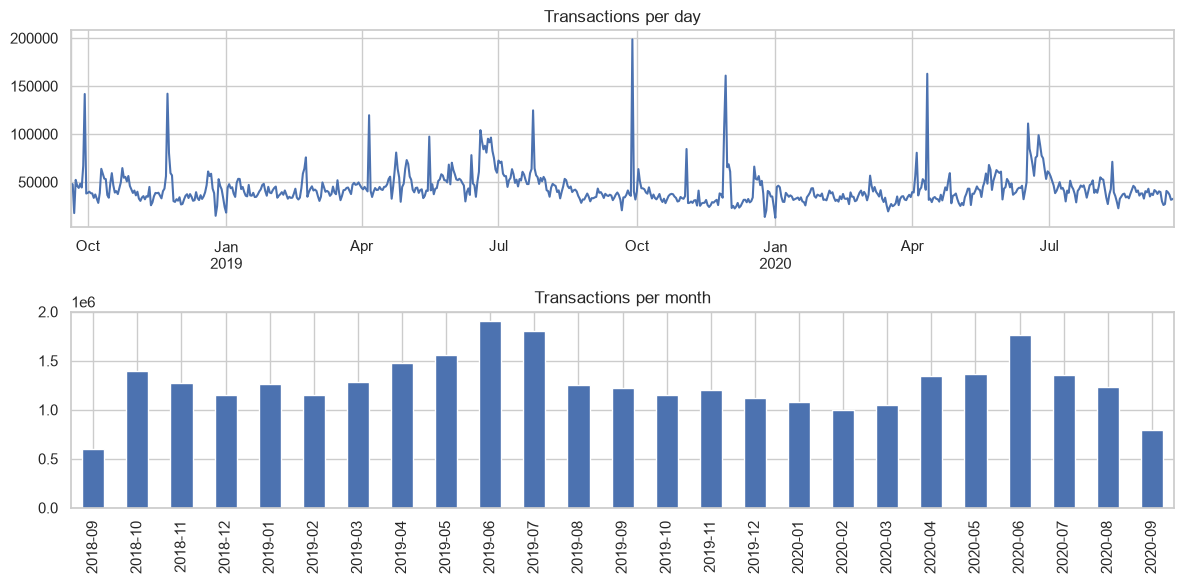

,mean transactions per day
t_dat,
Mon,"38,610.0381"
Tue,"39,986.9524"
Wed,"46,565.5865"
Thu,"46,291.3810"
Fri,"45,229.8286"
Sat,"48,090.4762"
Sun,"38,415.1619"


Calendar days with no transactions: 0


In [6]:
daily = audit["daily_counts"].sort_index()
fig, axes = plt.subplots(2, 1, figsize=(12, 6))
daily.plot(ax=axes[0], title="Transactions per day")
monthly = daily.groupby(daily.index.to_period("M")).sum()
monthly.plot(kind="bar", ax=axes[1], title="Transactions per month")
axes[0].set_xlabel(""); axes[1].set_xlabel("")
save_fig("transactions_over_time.png")
dow = daily.groupby(daily.index.dayofweek).mean().rename(index=dict(enumerate(["Mon","Tue","Wed","Thu","Fri","Sat","Sun"])))
display(dow.rename("mean transactions per day").to_frame())
missing_days = pd.date_range(audit["date_min"], audit["date_max"]).difference(daily.index)
print("Calendar days with no transactions:", len(missing_days))

### A5. User and item activity (full file)

,purchases per user,purchases per item
count,"1,362,281.0000","104,547.0000"
mean,23.3346,304.0577
std,39.2423,791.2661
min,1.0000,1.0000
50%,9.0000,65.0000
75%,27.0000,286.0000
90%,60.0000,793.0000
99%,187.0000,"3,185.0800"
max,"1,895.0000","50,287.0000"


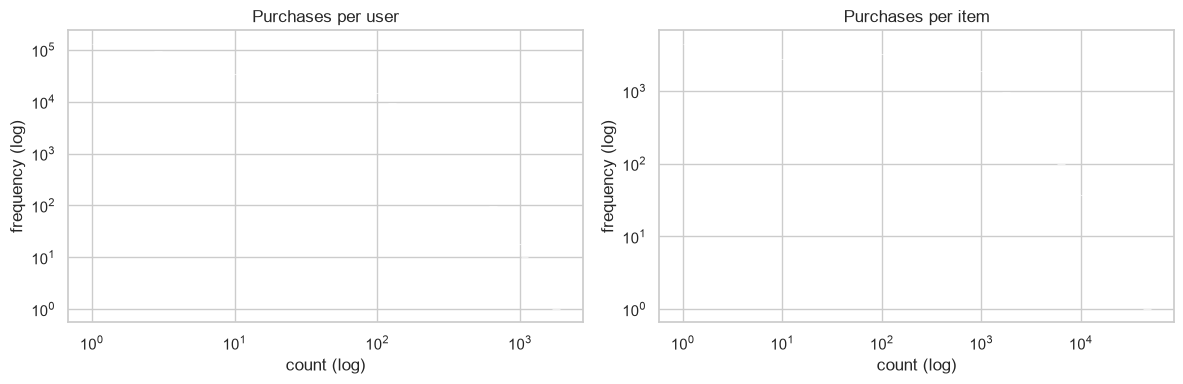

In [7]:
user_counts, item_counts = audit["user_counts"], audit["item_counts"]
display(pd.concat([da.describe_activity(user_counts).rename("purchases per user"),
                   da.describe_activity(item_counts).rename("purchases per item")], axis=1))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, counts, title in zip(axes, [user_counts, item_counts], ["Purchases per user", "Purchases per item"]):
    sns.histplot(counts, bins=60, log_scale=(True, True), ax=ax)
    ax.set_title(title); ax.set_xlabel("count (log)"); ax.set_ylabel("frequency (log)")
save_fig("activity_distributions.png")

### A6. Popularity concentration and cold start

Gini of purchases per item: 0.7586 | per user: 0.6456


,share of purchases held by top items,share of purchases made by top users
top 1%,0.1862,0.1164
top 5%,0.4404,0.3285
top 10%,0.6075,0.4847
top 20%,0.7910,0.6767


,share of purchasing users
<= 1 purchases,0.0965
<= 2 purchases,0.1901
<= 3 purchases,0.2603
<= 5 purchases,0.3680
<= 10 purchases,0.5289
<= 20 purchases,0.6894


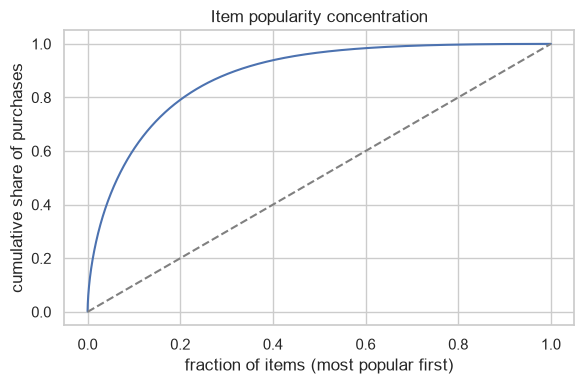

In [8]:
print("Gini of purchases per item:", round(da.gini(item_counts), 4), "| per user:", round(da.gini(user_counts), 4))
display(pd.concat([da.concentration_table(item_counts).rename("share of purchases held by top items"),
                   da.concentration_table(user_counts).rename("share of purchases made by top users")], axis=1))
display(da.cold_start_table(user_counts).rename("share of purchasing users").to_frame())

ranked = np.sort(item_counts.to_numpy())[::-1]
plt.figure(figsize=(6, 4))
plt.plot(np.arange(1, len(ranked) + 1) / len(ranked), np.cumsum(ranked) / ranked.sum())
plt.plot([0, 1], [0, 1], "--", color="grey")
plt.xlabel("fraction of items (most popular first)"); plt.ylabel("cumulative share of purchases")
plt.title("Item popularity concentration")
save_fig("item_popularity_curve.png")

## Part B. Metadata tables

In [9]:
customers = da.load_customers()
articles = da.load_articles()
print("articles:", articles.shape, "| customers:", customers.shape)

articles: (105542, 25) | customers: (1371980, 7)


### B1. Referential integrity between tables

In [10]:
da.referential_integrity(audit, customers, articles).to_frame('count')

,count
customer ids duplicated in customers.csv,0
article ids duplicated in articles.csv,0
transaction customers missing from customers.csv,0
transaction articles missing from articles.csv,0
customers with no transactions,9699
articles with no transactions,995


Customers with no transactions are cold-start users. Articles with no transactions are cold-start items; both matter for the cold-start discussion later.

### B2. Articles: completeness and cardinality

In [11]:
display(da.missing_summary(articles))
print("distinct product_code values:", articles["product_code"].nunique(), "for", len(articles), "articles")
colours_per_product = articles.groupby("product_code")["article_id"].nunique()
print("articles per product_code (colour/size variants): mean", round(colours_per_product.mean(), 2), "| max", colours_per_product.max())

,missing,missing_pct,n_unique
detail_desc,416,0.3942,43404
product_code,0,0.0000,47224
prod_name,0,0.0000,45875
product_type_no,0,0.0000,132
product_type_name,0,0.0000,131
product_group_name,0,0.0000,19
graphical_appearance_no,0,0.0000,30
graphical_appearance_name,0,0.0000,30
article_id,0,0.0000,105542
colour_group_code,0,0.0000,50


distinct product_code values: 47224 for 105542 articles
articles per product_code (colour/size variants): mean 2.23 | max 75


Several articles share one `product_code` (variants of the same design). Collaborative signals are split across such variants, so Week 2/3 should consider whether to model at article or product level.

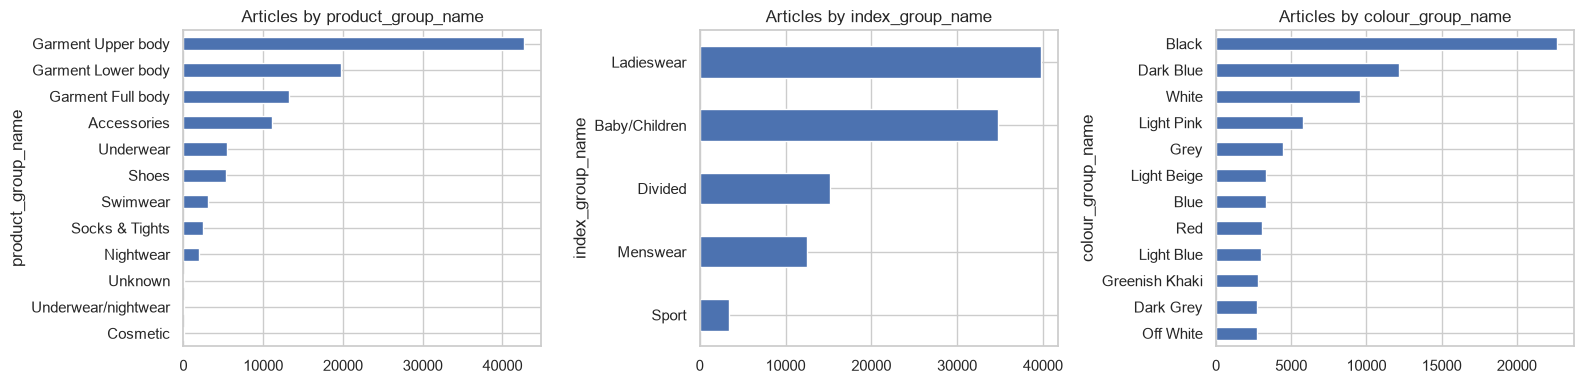

garment_group_name
Jersey Fancy         21445
Accessories          11519
Jersey Basic          8126
Knitwear              7490
Under-, Nightwear     7441
Trousers              6727
Blouses               5838
Shoes                 5145
Dresses Ladies        4874
Outdoor               4501
Unknown               3873
Trousers Denim        3100
Swimwear              2787
Socks and Tights      2272
Shirts                2116
Name: count, dtype: int64

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["product_group_name", "index_group_name", "colour_group_name"]):
    articles[col].value_counts().head(12).sort_values().plot(kind="barh", ax=ax, title=f"Articles by {col}")
save_fig("article_metadata_distributions.png")
display(articles["garment_group_name"].value_counts().head(15))

### B3. Article descriptions and images

In [13]:
desc = articles["detail_desc"].dropna()
print("articles with a description:", f"{len(desc) / len(articles):.2%}", "| median length (chars):", int(desc.str.len().median()))
print("article ids shorter than 10 digits (images need zero-padding):", int((articles["article_id"] < 1_000_000_000).sum()))
cov = da.image_coverage(articles)
print("Image folder not found at", config.ARTICLE_IMAGES_DIR if cov is None else f"image coverage: {cov:.2%}")

articles with a description: 99.61% | median length (chars): 132
article ids shorter than 10 digits (images need zero-padding): 105542
Image folder not found at C:\Users\HP\Documents\DSA4060\Final project\DSA4060XA-Recommender-Project-1\data\raw\images


### B4. Customers: completeness and demographics

,missing,missing_pct,n_unique
Active,907576,66.1508,1
FN,895050,65.2378,1
fashion_news_frequency,16011,1.1670,3
age,15861,1.1561,84
club_member_status,6062,0.4418,3
postal_code,0,0.0000,352899


count   1,356,119.0000
mean           36.3870
std            14.3136
min            16.0000
25%            24.0000
50%            32.0000
75%            49.0000
max            99.0000
Name: age, dtype: float64

,customers
club_member_status,
ACTIVE,1272491
PRE-CREATE,92960
NaN,6062
LEFT CLUB,467


,customers
fashion_news_frequency,
NONE,877711
Regularly,477416
NaN,16011
Monthly,842


postal_code distinct values: 352899 (anonymised hashes; not a usable location)


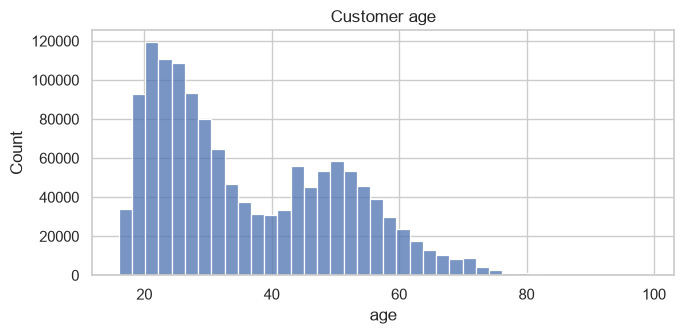

In [14]:
display(da.missing_summary(customers.drop(columns="customer_id")))
display(customers["age"].describe())
display(customers["club_member_status"].value_counts(dropna=False).to_frame("customers"))
display(customers["fashion_news_frequency"].value_counts(dropna=False).to_frame("customers"))
print("postal_code distinct values:", customers["postal_code"].nunique(), "(anonymised hashes; not a usable location)")
plt.figure(figsize=(7, 3.5)); sns.histplot(customers["age"].dropna(), bins=40); plt.title("Customer age")
save_fig("customer_age.png")

Note for the responsible-recommendation section: `age` is personal data and a possible fairness axis. Decide in Week 2 whether it is used as a feature at all.

## Part C. Working set (in-memory analyses)
`config.START_DATE` / `config.MAX_ROWS` control how much of the file is loaded. `None` means everything; reduce it if RAM is limited. Every number below describes **the working set**, which is stated in the next cell.

In [ ]:
tx = da.load_transactions(customer_ids=customers["customer_id"])
tx = tx[tx["customer_id"].notna()]
print(f"Working set: {len(tx):,} of {audit['rows']:,} rows | START_DATE={config.START_DATE} MAX_ROWS={config.MAX_ROWS}")
print(f"memory: {tx.memory_usage(deep=True).sum() / 1e9:.2f} GB")
ws = da.working_set_summary(tx)
ws

### C1. Requirements check and sparsity (working set)

In [ ]:
display(da.brief_requirements_check(len(tx), tx["customer_id"].nunique(), tx["article_id"].nunique()))
print(f"Sparsity: {ws['sparsity (share of empty matrix cells)']:.6%} of the user-item matrix is empty")

### C2. Repeat purchases of the same article

In [ ]:
rep = da.repeat_purchase_distribution(tx)
display(rep.head(10).to_frame())
print(f"Share of user-item pairs bought more than once: {rep[rep.index > 1].sum() / rep.sum():.2%}")

Fashion differs from movies here: repeats exist, so the interaction signal can be binary (bought or not) or weighted by count. This is a Week 2 design decision to justify.

### C3. Most active users and most popular items

In [ ]:
top_users = tx["customer_id"].value_counts().head(10).rename("purchases").to_frame()
display(top_users)
top_items = (tx["article_id"].value_counts().head(15).rename("purchases").to_frame()
             .join(articles.set_index("article_id")[["prod_name", "product_type_name", "product_group_name", "colour_group_name"]]))
display(top_items)

### C4. Price by product group

In [ ]:
priced = tx.merge(articles[["article_id", "product_group_name"]], on="article_id", how="left")
display(priced.groupby("product_group_name")["price"].agg(["count", "mean", "median"]).sort_values("count", ascending=False))
del priced

### C5. Seasonality by product group

In [ ]:
months = tx["t_dat"].dt.to_period("M")
grp = tx["article_id"].map(articles.set_index("article_id")["product_group_name"])
trend = pd.crosstab(months, grp)
top_groups = trend.sum().sort_values(ascending=False).head(6).index
trend[top_groups].plot(figsize=(12, 4), title="Monthly purchases by product group")
save_fig("monthly_trend_by_group.png")

### C6. Same-day baskets as outfit proxies

In [ ]:
baskets, cooc = da.basket_analysis(tx, articles)
display(baskets.describe(percentiles=[0.5, 0.9, 0.99]))
print(f"Baskets with 2+ items: {(baskets['basket_size'] >= 2).mean():.2%}")
print(f"Baskets with 2+ distinct product groups: {(baskets['distinct_product_groups'] >= 2).mean():.2%}")
display(baskets["basket_size"].clip(upper=10).value_counts().sort_index().rename("baskets (10 = 10 or more)").to_frame())

### C7. Which product groups are bought together?

In [ ]:
diag = np.diag(cooc.to_numpy()).astype(float)
lift_den = np.outer(diag, diag) / len(baskets)
lift_values = cooc.to_numpy() / lift_den
np.fill_diagonal(lift_values, np.nan)
lift = pd.DataFrame(lift_values, index=cooc.index, columns=cooc.columns)
plt.figure(figsize=(9, 6))
sns.heatmap(lift, annot=True, fmt=".2f", center=1, cmap="RdBu_r", cbar_kws={"label": "lift (1 = independent)"})
plt.title("Co-purchase lift between product groups within same-day baskets")
save_fig("group_cooccurrence_lift.png")
display(cooc)

Lift above 1 means two groups appear in the same basket more often than chance; this is direct evidence for (or against) a product-group complementarity layer in the hybrid model.

## Part D. Export and findings

In [ ]:
summary = {
    "full_file": {k: v for k, v in da.stream_summary(audit).items()},
    "full_file_requirements": da.brief_requirements_check(audit["rows"], len(user_counts), len(item_counts)).reset_index().to_dict("records"),
    "referential_integrity": da.referential_integrity(audit, customers, articles).to_dict(),
    "gini_items": da.gini(item_counts), "gini_users": da.gini(user_counts),
    "item_concentration": da.concentration_table(item_counts).to_dict(),
    "working_set": ws.to_dict(),
    "basket_share_2plus_items": float((baskets["basket_size"] >= 2).mean()),
    "basket_share_2plus_groups": float((baskets["distinct_product_groups"] >= 2).mean()),
    "image_coverage": cov,
}
da.export_summary(summary, config.DOCS_DIR / "audit_summary.json")
print("Wrote", config.DOCS_DIR / "audit_summary.json")

### Findings to carry into Week 2
Fill these in from the outputs above (write your own interpretation; the report needs your reasoning, not mine):

1. **Dataset size and the brief's minimums:** ...
2. **Sparsity and popularity skew (Gini, top-1% share):** ...
3. **Cold start (users with few purchases, articles never bought):** ...
4. **Repeat purchases and the choice of interaction signal (binary vs count):** ...
5. **Duplicates and missing values and how Week 2 will treat them:** ...
6. **Is the same-day basket a usable outfit proxy? Which product groups co-occur (lift)?** ...
7. **Filtering/sampling plan and the justification for it:** ...